# Speed

Because the marginalized statistic is a table lookup, the cost of a segment posterior is set by the grid, not by the signal to noise ratio.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT/'src')); sys.path.insert(0, str(ROOT/'examples'))
import numpy as np, matplotlib.pyplot as plt
from exmarg import figstyle, make_event, make_data
from exmarg.evaluate import SumEvaluator, mc_q_to_m1m2
from fetch_tables import ensure_nodes
figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## A small grid and its tables


In [2]:
mc_ax=np.linspace(27.0,29.0,6); q_ax=np.linspace(0.7,1.0,3); x_ax=np.linspace(-0.1,0.1,3)
us=[]
for mc in (mc_ax[0],mc_ax[-1]):
    for q in (q_ax[0],q_ax[-1]):
        for chi in (x_ax[0],x_ax[-1]):
            mm1,mm2=mc_q_to_m1m2(mc,q)
            cc=make_event(mm1,mm2,chi,chi,4.0,25.0,512.0,sky=(1.2,2.0),psi_s=0.4,chi_s=0.3)
            us.append(cc.u['H'])
stems=ensure_nodes(u_lo=min(us)*0.95,u_hi=max(us)*1.05)
grid=[(mc_q_to_m1m2(mc,q),chi) for mc in mc_ax for q in q_ax for chi in x_ax]
print('%d templates, %d table nodes'%(len(grid),len(stems)))

54 templates, 5 table nodes


## Time the sweep at each injected SNR

The same event is injected at increasing loudness (nearer distance); the grid sweep is timed after a warm-up that pages in the tables.


In [3]:
m1,m2=mc_q_to_m1m2(28.0,0.8)
case=make_event(m1,m2,0.1,0.1,4.0,25.0,512.0,sky=(1.2,2.0),psi_s=0.4,chi_s=0.3)
SNRS=[2,4,6,10,16,25]; walls=[]
for rho in SNRS:
    d=make_data(case,7,inject=True,phi_s=0.7,t_s=2.0,y_s=rho/case.rho_mf)
    ev=SumEvaluator(case,d,stems,tc=2.0,dt=0.55)
    ev.lnlam(*grid[0][0],grid[0][1])          # warm-up (page-in), untimed
    t0=time.time()
    for (mm1,mm2),chi in grid: ev.lnlam(mm1,mm2,chi)
    walls.append(time.time()-t0)
    print('rho=%2d  sweep %.2f s (%.1f ms/template)'%(rho,walls[-1],1e3*walls[-1]/len(grid)))

rho= 2  sweep 4.88 s (90.4 ms/template)


rho= 4  sweep 4.84 s (89.6 ms/template)


rho= 6  sweep 4.75 s (88.0 ms/template)


rho=10  sweep 4.85 s (89.8 ms/template)


rho=16  sweep 4.79 s (88.8 ms/template)


rho=25  sweep 4.92 s (91.1 ms/template)


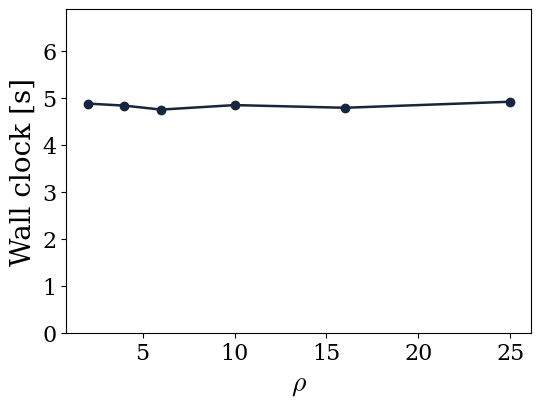

In [4]:
fig,ax=plt.subplots(figsize=(6.0,4.2))
ax.plot(SNRS,walls,'o-',color=figstyle.NAVY,lw=1.8,ms=6)
ax.set_ylim(0,max(walls)*1.4); ax.set_xlabel(r'$\rho$')
ax.set_ylabel('Wall clock [s]')
np.savez('data/fig15_speed_live.npz',snrs=SNRS,walls=walls,n_template=len(grid))
plt.show()